In [5]:
print("hello world") 

hello world


In [6]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score 

### Data Load

In [7]:
financial_df = pd.read_csv("../data/raw_data/cs-training.csv") 

financial_df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


### Data Preprocessing

In [8]:
financial_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 11  

In [9]:
financial_df.describe()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,75000.500000,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,43301.414527,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,37500.750000,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,75000.500000,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,112500.250000,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,150000.000000,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [10]:
financial_df.isnull().sum()

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [11]:
# Handle Missing Values 

missing_values_income = SimpleImputer(strategy = 'mean') 
financial_df[['MonthlyIncome']] = missing_values_income.fit_transform(financial_df[['MonthlyIncome']])

missing_values_dependents = SimpleImputer(strategy = 'median') 
financial_df[['NumberOfDependents']] = missing_values_dependents.fit_transform(financial_df[['NumberOfDependents']])

financial_df.isnull().sum()

Unnamed: 0                              0
SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64

### Exploratory Data Analysis (EDA) 

- SeriousDlqin2yrs means Wheather a person experienced a seriously overdue credit payment within a two-year period. 

In [12]:
financial_df.rename(columns = {'SeriousDlqin2yrs' : 'Serious_Delinquency_Within_2Y'}, inplace = True)  

In [13]:
financial_df.columns

Index(['Unnamed: 0', 'Serious_Delinquency_Within_2Y',
       'RevolvingUtilizationOfUnsecuredLines', 'age',
       'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
       'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
       'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
       'NumberOfDependents'],
      dtype='object')

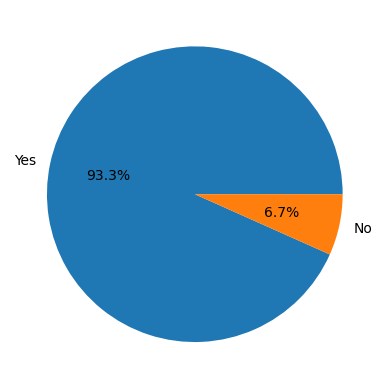

In [14]:
approval_counts = financial_df['Serious_Delinquency_Within_2Y'].value_counts() 

plt.pie(approval_counts, autopct = '%.1f%%', labels = ['Yes', 'No'])
plt.show() 

- Insight:- Class imbalance. 

In [15]:
clean_df = financial_df.drop(columns = ['Unnamed: 0'], axis = 1)

clean_df.head(2)

,Serious_Delinquency_Within_2Y,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0


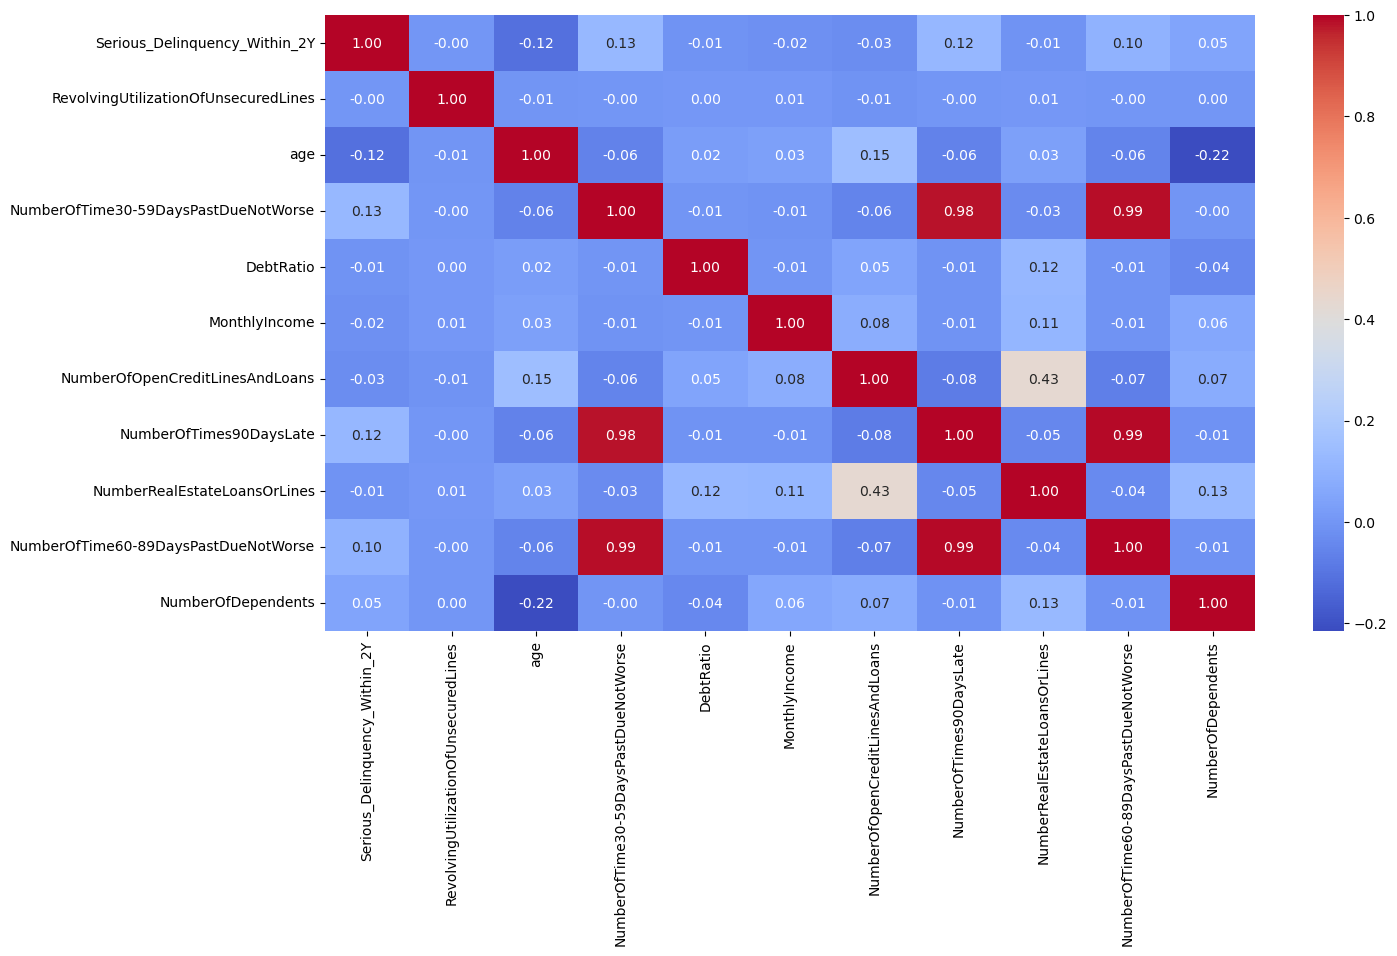

In [16]:
numeric_cols = clean_df.select_dtypes(include = 'number') 

correlation_matrix = numeric_cols.corr() 

plt.figure(figsize = (15, 8)) 
sns.heatmap(correlation_matrix, fmt = '.2f', cmap = 'coolwarm', annot = True) 
plt.show() 

In [17]:
clean_df.corr()['Serious_Delinquency_Within_2Y'].sort_values(ascending = False) 

Serious_Delinquency_Within_2Y           1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046869
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.018002
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: Serious_Delinquency_Within_2Y, dtype: float64

- __Insights:__

1. Previous payment delays are assoicated with hgiher delinquency risk

- NumberOfTime30-59DaysPastDueNotWorse has a positive correlation of 0.125557.

Insight:- Customers with a history of delaped payment tend to have higher likelihood of experiencing serious delinquency within two years. Previous repayment behaviour is therefore an import feature for credit risk prediction. 

2. Customer age has the strongest negative correlction

- age has a correlation of -0.115386, the strongest negative (Perfect Negative correlation) in the result.

Insight:- In this dataset, older customers tend to have a lower likelihood of serious delinquency compared with younger customers. 

### Feature Selections

In [18]:
clean_df.columns

Index(['Serious_Delinquency_Within_2Y', 'RevolvingUtilizationOfUnsecuredLines',
       'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio',
       'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans',
       'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines',
       'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents'],
      dtype='object')

In [19]:
X = clean_df.drop(columns = 'Serious_Delinquency_Within_2Y', axis = 1)
y = clean_df['Serious_Delinquency_Within_2Y'] 

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, stratify = y, random_state = 42
)

### Feature Scaling

In [21]:
scaler = StandardScaler() 

X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test) 

In [22]:
X_train_scaled

array([[-0.02420919, -0.22205023, -0.10077858, ..., -0.90337056,
        -0.05739561, -0.66744134],
       [-0.02408556, -1.03500979, -0.10077858, ..., -0.01714219,
        -0.05739561,  0.23665904],
       [-0.02417951, -0.89951653, -0.10077858, ..., -0.01714219,
        -0.05739561, -0.66744134],
       ...,
       [-0.02420919, -0.22205023, -0.10077858, ..., -0.01714219,
        -0.05739561,  0.23665904],
       [-0.02075417,  0.7264026 , -0.10077858, ..., -0.90337056,
        -0.05739561, -0.66744134],
       [-0.02047479, -0.76402327,  0.14162191, ..., -0.90337056,
         0.18730714, -0.66744134]])

### Model Training & Evalution

In [23]:
from sklearn.linear_model import LogisticRegression 

In [24]:
logistic_model = LogisticRegression(class_weight = 'balanced', max_iter = 1000)

logistic_model.fit(X_train_scaled, y_train) 

LogisticRegression(class_weight='balanced', max_iter=1000)

In [25]:
y_pred_train = logistic_model.predict(X_train_scaled)
y_pred_test = logistic_model.predict(X_test_scaled) 

y_pred_test

array([0, 0, 0, ..., 0, 0, 0])

In [26]:
print("Training Accuracy Score:- ", accuracy_score(y_train, y_pred_train))
print("Testing Accuracy Score:- ", accuracy_score(y_test, y_pred_test))

print("Training Precision Score:- ", precision_score(y_train, y_pred_train))
print("Testing Precision Score:- ", precision_score(y_test, y_pred_test))

print("Training Recall Score:- ", recall_score(y_train, y_pred_train)) 
print("Testing Recall Score:- ", recall_score(y_test, y_pred_test)) 

Training Accuracy Score:-  0.7729142857142857
Testing Accuracy Score:-  0.7763555555555556
Training Precision Score:-  0.17544942519867293
Testing Precision Score:-  0.1799709724238026
Training Recall Score:-  0.6480478768880022
Testing Recall Score:-  0.6595744680851063


In [27]:
from sklearn.naive_bayes import BernoulliNB

In [28]:
naive_model = BernoulliNB()

naive_model.fit(X_train_scaled, y_train) 

BernoulliNB()

In [29]:
y_pred_naive_train = naive_model.predict(X_train_scaled)
y_pred_naive_test = naive_model.predict(X_test_scaled)

y_pred_naive_train

array([0, 0, 0, ..., 0, 0, 1])

In [30]:
print("Training Accuracy Score:- ", accuracy_score(y_train, y_pred_naive_train))
print("Testing Accuracy Score:- ", accuracy_score(y_test, y_pred_naive_test))

print("Training Precision Score:- ", precision_score(y_train, y_pred_naive_train))
print("Testing Precision Score:- ", precision_score(y_test, y_pred_naive_test))

print("Training Recall Score:- ", recall_score(y_train, y_pred_naive_train)) 
print("Testing Recall Score:- ", recall_score(y_test, y_pred_naive_test)) 

Training Accuracy Score:-  0.9292190476190476
Testing Accuracy Score:-  0.9304666666666667
Training Precision Score:-  0.45595744680851064
Testing Precision Score:-  0.468733850129199
Training Recall Score:-  0.3053576517526361
Testing Recall Score:-  0.3015292553191489


In [31]:
from sklearn.tree import DecisionTreeClassifier

In [32]:
decision_model = DecisionTreeClassifier(max_depth = 4, random_state=42) 

decision_model.fit(X_train_scaled, y_train) 

DecisionTreeClassifier(max_depth=4, random_state=42)

In [33]:
y_pred_dec_train = decision_model.predict(X_train_scaled)
y_pred_dec_test = decision_model.predict(X_test_scaled)

y_pred_dec_test

array([0, 0, 0, ..., 0, 0, 0])

In [34]:
print("Training Accuracy Score:- ", accuracy_score(y_train, y_pred_dec_train)) 
print("Testing Accuracy Score:- ", accuracy_score(y_test, y_pred_dec_test)) 

print("Training Precision Score:- ", precision_score(y_train, y_pred_dec_train)) 
print("Testing Precision Score:- ", precision_score(y_test, y_pred_dec_test)) 

print("Training Recall Score:- ", recall_score(y_train, y_pred_dec_train))
print("Testing Recall Score:- ", recall_score(y_test, y_pred_dec_test)) 

Training Accuracy Score:-  0.9365904761904762
Testing Accuracy Score:-  0.9343333333333333
Training Precision Score:-  0.5954400848356309
Testing Precision Score:-  0.5342820181112549
Training Recall Score:-  0.16001709888857224
Testing Recall Score:-  0.1373005319148936


In [35]:
from sklearn.ensemble import RandomForestClassifier

In [36]:
random_model = RandomForestClassifier(n_estimators=300, max_depth = 8, min_samples_leaf = 20, 
                                      class_weight = 'balanced_subsample', random_state = 42, n_jobs = -1)

random_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced_subsample', max_depth=8,
                       min_samples_leaf=20, n_estimators=300, n_jobs=-1,
                       random_state=42)

In [37]:
y_pred_random_train = random_model.predict(X_train_scaled) 
y_pred_random_test = random_model.predict(X_test_scaled) 

y_pred_random_train

array([0, 0, 0, ..., 0, 1, 1])

In [38]:
print("Training Accuracy Score:- ", accuracy_score(y_train, y_pred_random_train)) 
print("Testing Accuracy Score:- ", accuracy_score(y_test, y_pred_random_test)) 

print("Training Precision Score:- ", precision_score(y_train, y_pred_random_train)) 
print("Testing Precision Score:- ", precision_score(y_test, y_pred_random_test)) 

print("Training Recall Score:- ", recall_score(y_train, y_pred_random_train))
print("Testing Recall Score:- ", recall_score(y_test, y_pred_random_test)) 

Training Accuracy Score:-  0.7931619047619047
Testing Accuracy Score:-  0.7913777777777777
Training Precision Score:-  0.21577726218097448
Testing Precision Score:-  0.21063134978229317
Training Recall Score:-  0.7950983186092904
Testing Recall Score:-  0.7719414893617021


- The above Situation is bais-variance trade-off to overcome the trade-off I'm using XGBoost algorithm. 

In [39]:
import xgboost as xgb 
from sklearn.metrics import (precision_recall_curve, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report) 

In [40]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size = 0.2, stratify = y_train, random_state = 42
)

ratio = (y_tr == 0).sum() / (y_tr == 1 ).sum() 


xgb_model = xgb.XGBClassifier(
    n_estimators = 1000,
    max_depth = 4, 
    learning_rate = 0.3, 
    min_child_weight = 5, 
    subsample = 0.8, 
    colsample_bytree = 0.8,
    reg_lambda = 5, gamma = 1, 
    scale_pos_weight = np.sqrt(ratio), 
    tree_method = 'hist', eval_metric = 'aucpr', 
    early_stopping_rounds = 50, random_state = 42
)

xgb_model.fit(X_tr, y_tr, eval_set = [(X_val, y_val)], verbose = False) 

# threshold chosen on validation data only
pv = xgb_model.predict_proba(X_val)[:, 1] # predict_proba = predict the probability. 
p, r, t = precision_recall_curve(y_val, pv) # p = precison, r = recall and t = threshold. 

f1 = 2* p[: -1] * r[: -1] / (p[: -1] + r[: -1] + 1e-9)  # formula f1 = 2 x precision x recall / (precision + recall).  # [: -1 ] means p and r have one extra value at the end  (p 1, r 0) that has no threshold. [: -1] drops it so all three lists have the same length. +1e-9 is a tiny number that prevents division by zero if (p, r) both are 0.
thr = t[np.argmax(f1)] # np.argmax(f1) means finds the position of the highest F1 score and threshold at that presition. 

for name, Xa, ya in [("Train", X_train, y_train), ("Test", X_test, y_test)]: # Training and Testing data 
    proba = xgb_model.predict_proba(Xa)[:, 1]
    pred = (proba >= thr).astype(int) # If probability is greater than threshold then return True or falase then I convert it into 1 ro 0.
    print(f"{name}: Precision={precision_score(ya, pred):.3f} Recall={recall_score(ya, pred):.3f}"
          f"F1 = {f1_score(ya, pred):.3f} ROC-AUC = {roc_auc_score(ya, proba):.3f}"
          f"PR-AUC = {average_precision_score(ya, proba):.3f}") 

test_pred = (xgb_model.predict_proba(X_test)[:, 1] >= thr).astype(int)
print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred)) 
             

Train: Precision=0.394 Recall=0.540F1 = 0.456 ROC-AUC = 0.873PR-AUC = 0.421
Test: Precision=0.385 Recall=0.528F1 = 0.445 ROC-AUC = 0.864PR-AUC = 0.400
[[39456  2536]
 [ 1421  1587]]
              precision    recall  f1-score   support

           0       0.97      0.94      0.95     41992
           1       0.38      0.53      0.45      3008

    accuracy                           0.91     45000
   macro avg       0.68      0.73      0.70     45000
weighted avg       0.93      0.91      0.92     45000



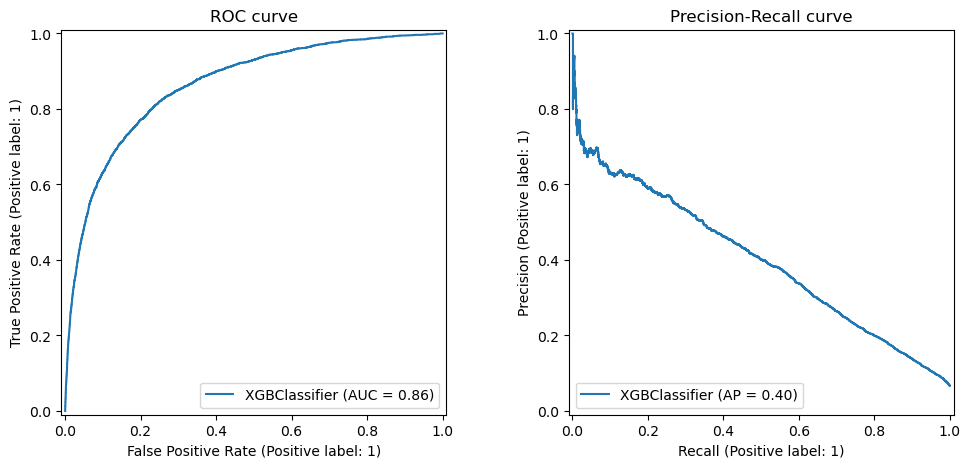

In [41]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_estimator(xgb_model, X_test, y_test, ax=ax[0])
PrecisionRecallDisplay.from_estimator(xgb_model, X_test, y_test, ax=ax[1])
ax[0].set_title("ROC curve")
ax[1].set_title("Precision-Recall curve")
plt.show()

<Axes: >

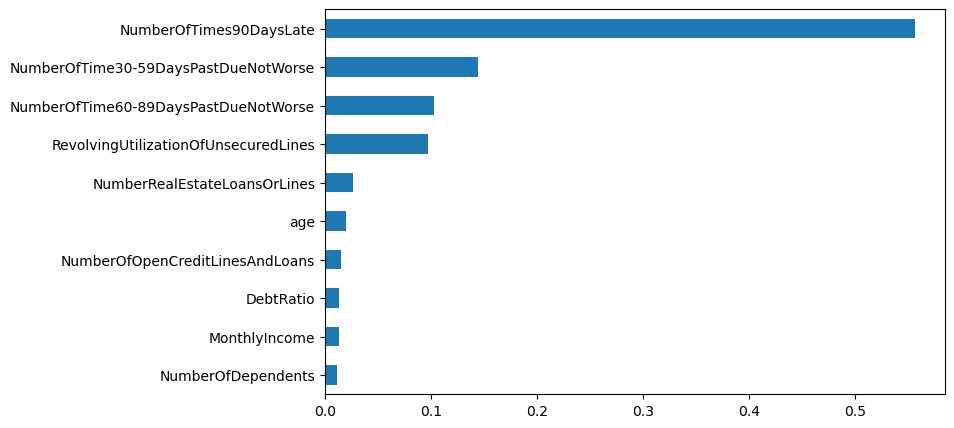

In [42]:
pd.Series(xgb_model.feature_importances_, index = X.columns).sort_values().plot.barh(figsize = (8, 5))

### Save the model and threshold 

In [43]:
import joblib

In [44]:
joblib.dump({
    'model': xgb_model, 
    'threshold' : float(thr),
    'features' : list(X.columns),
    'fill_values' : {
        'MonethlyIncome' : float(missing_values_income.statistics_[0]),
        'NumberOfDependents' : float(missing_values_dependents.statistics_[0]),
    }, 
    
}, 'credit_risk_xgb.joblib'  
)

['credit_risk_xgb.joblib']